# 5. Model Fit: Overfitting on Fashion-MNIST (Solution)

Last week we built our first neural network with `PyTorch` and, in the last coding task, tracked training and test accuracy after every epoch.
This week we take that network to a harder dataset and then **deliberately make it overfit**, so we can see what overfitting looks like in the loss and accuracy curves.

We follow the lecture: we split the data into **training**, **validation** and **test** data, train on the training data, watch the validation data during training, and use the test data only once at the very end.

## Part 1: Make the network overfit

### Load Fashion-MNIST

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) has the same format as MNIST: 70,000 grayscale images of 28x28 = 784 pixels, 10 classes.
But instead of digits, the images show clothing items, which makes the task considerably harder.
We load it the same way as MNIST last week (the first download takes a minute):

In [1]:
from sklearn.datasets import fetch_openml
X, y = fetch_openml('Fashion-MNIST', version=1, return_X_y=True, cache=True, parser='auto')
X.shape

(70000, 784)

The data looks exactly like MNIST, one column per pixel:

In [2]:
X.head(3)

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,119,114,130,76,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,22,...,0,0,1,0,0,0,0,0,0,0


The label is again a number between 0-9, but now each number stands for a type of clothing:

In [3]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
y.head(3)

0    9
1    0
2    0
Name: class, dtype: category
Categories (10, object): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

Let's look at one example image per class:

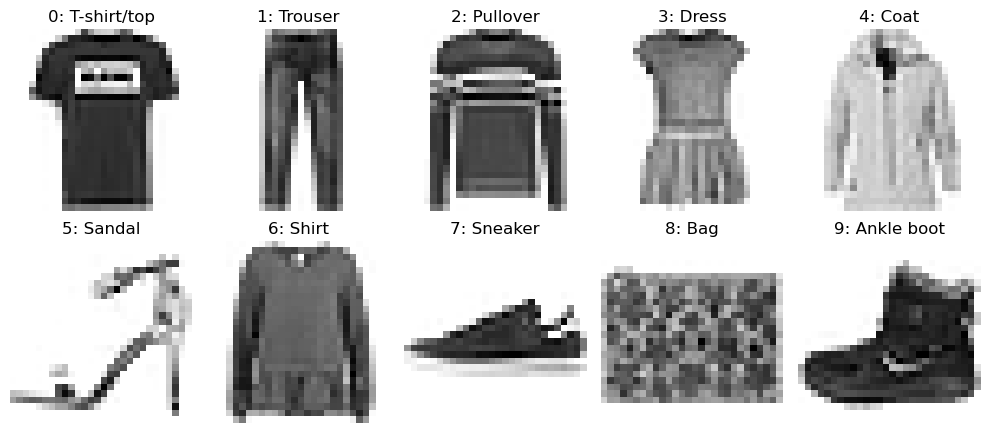

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for label, ax in enumerate(axes.flat):
    idx = (y.astype(int) == label).values.argmax()   # first image with this label
    ax.imshow(X.iloc[idx].values.reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{label}: {class_names[label]}")
    ax.axis("off")
plt.tight_layout()

### Prepare the data: train, validation and test

We scale the pixels to [0, 1] as last week. Then we split the data into three parts:
- **Test data:** the last 10,000 images (this is the official Fashion-MNIST test set). We only use it at the very end.
- **Validation data:** 10,000 images that we evaluate after every epoch to monitor overfitting.
- **Training data:** we use only **5,000** images. This keeps training fast on a CPU, and it makes overfitting appear within a few hundred epochs. (Less training data is also one of the reasons for overfitting from the lecture.)

In [5]:
from sklearn.model_selection import train_test_split

X_scaled = (X/255).astype('float32').values
y = y.astype('long').values

X_pool, y_pool = X_scaled[:60000], y[:60000]   # official training part
X_test, y_test = X_scaled[60000:], y[60000:]   # official test part

X_train, X_val, y_train, y_val = train_test_split(
    X_pool, y_pool, train_size=5000, test_size=10000, random_state=42, stratify=y_pool)
X_train.shape, X_val.shape, X_test.shape

((5000, 784), (10000, 784), (10000, 784))

As last week, we select the device and convert everything into PyTorch tensors:

In [6]:
import torch
import torch.nn as nn
torch.manual_seed(0) # to ensure reproducibility

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [7]:
train_x = torch.Tensor(X_train).float().to(device)
val_x = torch.Tensor(X_val).float().to(device)
test_x = torch.Tensor(X_test).float().to(device)
train_y = torch.Tensor(y_train).long().to(device)
val_y = torch.Tensor(y_val).long().to(device)
test_y = torch.Tensor(y_test).long().to(device)

### A reusable training function

We will train several networks, so we put last week's training loop (including the accuracy tracking from coding task 3) into a function.
After every epoch it measures loss and accuracy on the training **and** the validation data and stores them in a dictionary `history`.

Note that we evaluate in `eval()` mode and inside `torch.no_grad()`: we do not need gradients for evaluation, and some layers (e.g. dropout) behave differently during training and evaluation.

In [8]:
loss_func = nn.CrossEntropyLoss()

def evaluate(model, x, y):
    """Returns (loss, accuracy) of the model on the data x, y."""
    model.eval()
    with torch.no_grad():
        y_hat = model(x)
        loss = loss_func(y_hat, y).item()
        accuracy = (torch.argmax(y_hat, 1) == y).float().mean().item()
    return loss, accuracy


def train(model, optimizer, no_epochs, print_every=100):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(no_epochs):

        model.train()   # evaluate() below switches to eval mode, so switch back every epoch (matters for dropout)
        optimizer.zero_grad()
        y_hat = model(train_x)            # all training points (= batch gradient descent)
        loss = loss_func(y_hat, train_y)
        loss.backward()
        optimizer.step()

        train_loss, train_acc = evaluate(model, train_x, train_y)
        val_loss, val_acc = evaluate(model, val_x, val_y)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if epoch % print_every == 0:
            print(f"Epoch {epoch}: train loss {train_loss:.3f}, val loss {val_loss:.3f}, "
                  f"train acc {train_acc:.3f}, val acc {val_acc:.3f}")
    return history

And a function that plots loss and accuracy curves next to each other. The dashed line marks the epoch with the lowest validation loss:

In [9]:
import numpy as np

def plot_history(history, title=""):
    best_epoch = int(np.argmin(history["val_loss"]))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history["train_loss"], label="training loss")
    ax1.plot(history["val_loss"], label="validation loss")
    ax1.set_xlabel("number of epochs"); ax1.set_ylabel("loss")
    ax2.plot(history["train_acc"], label="training accuracy")
    ax2.plot(history["val_acc"], label="validation accuracy")
    ax2.set_xlabel("number of epochs"); ax2.set_ylabel("accuracy")
    for ax in (ax1, ax2):
        ax.axvline(best_epoch, color="gray", linestyle="--", label=f"lowest val loss (epoch {best_epoch})")
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

The curves can be a bit noisy from epoch to epoch. To compare models, we therefore average the last 20 epochs:

In [10]:
def summary(history, name=""):
    """Averages over the last 20 epochs: train acc, val acc, gap, val loss."""
    train_acc = np.mean(history["train_acc"][-20:])
    val_acc = np.mean(history["val_acc"][-20:])
    val_loss = np.mean(history["val_loss"][-20:])
    gap = train_acc - val_acc
    if name:
        print(f"{name:22s}: train acc {train_acc:.3f}, val acc {val_acc:.3f}, gap {gap:.3f}, "
              f"val loss {val_loss:.3f} (lowest: {min(history['val_loss']):.3f})")
    return train_acc, val_acc, gap, val_loss

### Step 1: Last week's network on Fashion-MNIST

We start with the network from last week. For training we now use the **Adam** optimizer (see the gradient descent variants from week 3) instead of plain SGD. We use the same optimizer settings for all networks in this notebook, so that differences between the networks come from the architecture, not from the optimizer.

### Task 1: Define last week's network
Write a class `DeepNeuralNetwork` (inheriting from `nn.Module`) with a constructor `__init__` and a `forward` method. The network has the following layers:
- Input layer of size 784
- First hidden layer of size 128 with sigmoid activation
- Second hidden layer of size 64 with sigmoid activation
- Output layer of size 10 (no activation, the softmax is part of `CrossEntropyLoss`)

In [11]:
class DeepNeuralNetwork(nn.Module):
    def __init__(self):
        super(DeepNeuralNetwork, self).__init__()
        self.hidden1 = nn.Linear(784, 128)
        self.hidden2 = nn.Linear(128, 64)
        self.output = nn.Linear(64, 10)

    def forward(self, x):
        z1 = self.hidden1(x)
        a1 = torch.sigmoid(z1)
        z2 = self.hidden2(a1)
        a2 = torch.sigmoid(z2)
        z3 = self.output(a2)
        return z3

In [12]:
# check for task 1: do not change this cell
test_model = DeepNeuralNetwork()
n_params = sum(p.numel() for p in test_model.parameters())
assert n_params == 109386, f"DeepNeuralNetwork has {n_params} parameters, but should have 109,386 - check the layer sizes"
assert test_model(torch.zeros(2, 784)).shape == (2, 10), "the network should return 10 scores per image"
print("All checks passed!")

All checks passed!


Now we create the network and train it:

In [13]:
torch.manual_seed(0)
dnn = DeepNeuralNetwork().to(device)
print("Number of parameters:", sum(p.numel() for p in dnn.parameters()))

optimizer = torch.optim.Adam(dnn.parameters(), lr=0.0005)
history_small = train(dnn, optimizer, no_epochs=300, print_every=30)

Number of parameters: 109386
Epoch 0: train loss 2.361, val loss 2.361, train acc 0.100, val acc 0.100
Epoch 30: train loss 2.150, val loss 2.151, train acc 0.331, val acc 0.338
Epoch 60: train loss 1.860, val loss 1.859, train acc 0.371, val acc 0.372
Epoch 90: train loss 1.626, val loss 1.624, train acc 0.492, val acc 0.498
Epoch 120: train loss 1.452, val loss 1.450, train acc 0.548, val acc 0.551
Epoch 150: train loss 1.312, val loss 1.310, train acc 0.571, val acc 0.573
Epoch 180: train loss 1.196, val loss 1.194, train acc 0.603, val acc 0.598
Epoch 210: train loss 1.096, val loss 1.096, train acc 0.636, val acc 0.632
Epoch 240: train loss 1.008, val loss 1.009, train acc 0.671, val acc 0.665
Epoch 270: train loss 0.931, val loss 0.934, train acc 0.691, val acc 0.685


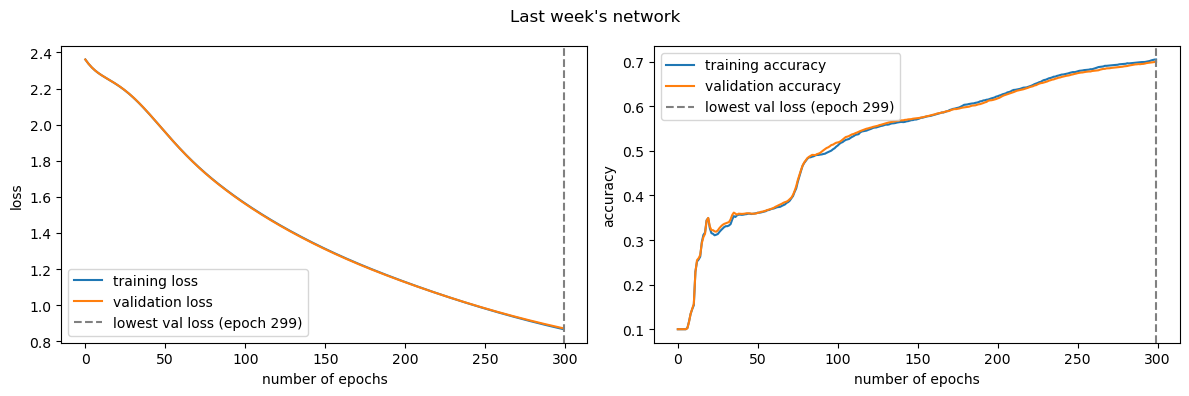

In [14]:
plot_history(history_small, "Last week's network")

**Question:** Is this model overfitting, underfitting, or well fitted? Look at both the gap between the curves and at how the curves are behaving at the end of training.

*Your answer:* ...

*Answer:* Underfitting. Training and validation curves lie almost on top of each other (small gap), but the accuracy is still low and both losses are still decreasing at the end of training. The model has not yet fully learned the training data, so more capacity and/or a better optimizer could help.

### Step 2: Extend the network until it overfits

To provoke overfitting we give the network much more **capacity** (see lecture). We make two changes:
1. **Wider and deeper:** three hidden layers with 512, 512 and 256 neurons.
2. **ReLU** instead of sigmoid in the hidden layers, so that the deeper network trains well.

### Task 2: Define the extended network
Write a class `BigNetwork` in the same way as `DeepNeuralNetwork` in Task 1, i.e. implement the constructor `__init__` and the `forward` method. The network has the following layers:
- Input layer of size 784
- First hidden layer of size 512 with ReLU activation
- Second hidden layer of size 512 with ReLU activation
- Third hidden layer of size 256 with ReLU activation
- Output layer of size 10 (no activation, as last week)

Hint: `torch.relu` works just like `torch.sigmoid`.

In [15]:
class BigNetwork(nn.Module):
    def __init__(self):
        super(BigNetwork, self).__init__()
        self.hidden1 = nn.Linear(784, 512)
        self.hidden2 = nn.Linear(512, 512)
        self.hidden3 = nn.Linear(512, 256)
        self.output = nn.Linear(256, 10)

    def forward(self, x):
        a1 = torch.relu(self.hidden1(x))
        a2 = torch.relu(self.hidden2(a1))
        a3 = torch.relu(self.hidden3(a2))
        z4 = self.output(a3)
        return z4

In [16]:
# check for task 2: do not change this cell
test_model = BigNetwork()
n_params = sum(p.numel() for p in test_model.parameters())
assert n_params == 798474, f"BigNetwork has {n_params} parameters, but should have 798,474 - check the layer sizes"
assert test_model(torch.zeros(2, 784)).shape == (2, 10), "the network should return 10 scores per image"
print("All checks passed!")

All checks passed!


Now we create the network and compare its size with the amount of training data:

In [17]:
torch.manual_seed(0)
big = BigNetwork().to(device)
print("Number of parameters:", sum(p.numel() for p in big.parameters()))
print("Number of training images:", len(train_x))

Number of parameters: 798474
Number of training images: 5000


The network now has about 800,000 parameters, i.e. more than 150 parameters per training image. We train it with the same settings as before (this takes about one or two minutes on a CPU):

In [18]:
optimizer = torch.optim.Adam(big.parameters(), lr=0.0005)
history_big = train(big, optimizer, no_epochs=300, print_every=30)

Epoch 0: train loss 2.272, val loss 2.272, train acc 0.154, val acc 0.155
Epoch 30: train loss 0.672, val loss 0.662, train acc 0.735, val acc 0.741
Epoch 60: train loss 0.481, val loss 0.505, train acc 0.826, val acc 0.822
Epoch 90: train loss 0.395, val loss 0.459, train acc 0.862, val acc 0.840
Epoch 120: train loss 0.324, val loss 0.434, train acc 0.886, val acc 0.848
Epoch 150: train loss 0.272, val loss 0.434, train acc 0.906, val acc 0.850
Epoch 180: train loss 0.224, val loss 0.441, train acc 0.925, val acc 0.849
Epoch 210: train loss 0.183, val loss 0.454, train acc 0.941, val acc 0.850
Epoch 240: train loss 0.158, val loss 0.491, train acc 0.947, val acc 0.848
Epoch 270: train loss 0.143, val loss 0.535, train acc 0.952, val acc 0.840


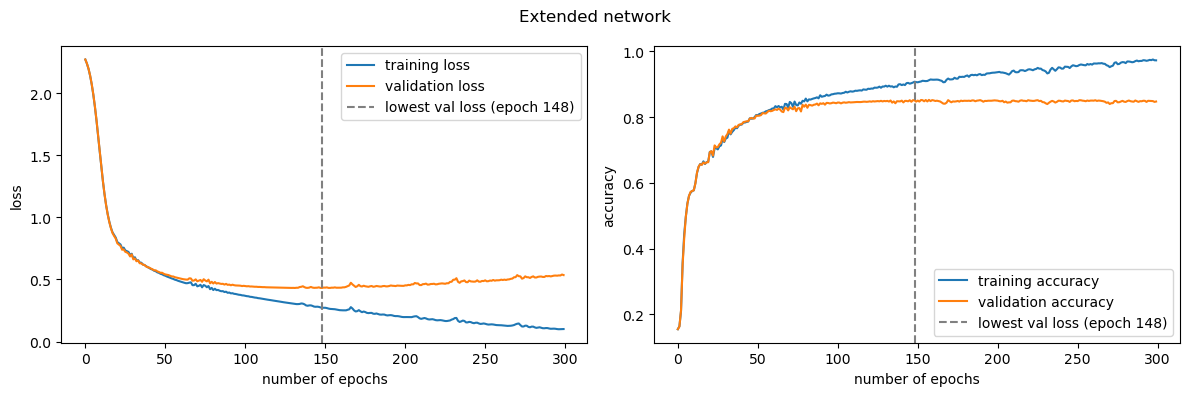

In [19]:
plot_history(history_big, "Extended network")

This is the textbook picture of overfitting:
- The **training loss** keeps decreasing towards zero and the training accuracy approaches 100%: the network starts to memorize the 5,000 training images.
- The **validation loss** reaches its minimum early (dashed line) and then *increases* again, while the validation accuracy stagnates. Compare this with the loss/capacity plots in the lecture.
- The gap between training and validation accuracy is now much larger than in Step 1.

In [20]:
summary(history_small, "last week's network")
summary(history_big, "extended network");

last week's network   : train acc 0.699, val acc 0.695, gap 0.004, val loss 0.891 (lowest: 0.872)
extended network      : train acc 0.971, val acc 0.848, gap 0.123, val loss 0.527 (lowest: 0.431)


**Question:** After the dashed line, the validation *loss* rises again, but the validation *accuracy* stays almost the same. How can both be true at the same time?
(Hint: cross-entropy does not only look at whether a prediction is correct, but also at how confident it is.)

*Your answer:* ...

*Answer:* Accuracy only checks whether the class with the highest score is correct. The cross-entropy loss also punishes how confident the prediction is. After the best epoch the network becomes more and more confident on the training data, so for the validation images it gets wrong, it is now wrong with a very high confidence, which makes the loss very large. The number of correct predictions hardly changes, so the accuracy stays flat while the loss goes up.